In [6]:
import numpy as np

In [36]:
# Rosenbrock function and its gradient
def rosenbrock(v):
    x, y = v
    f = (1 - x)**2 + 100*(y - x**2)**2
    return f

def grad_rosenbrock(v):
    x, y = v
    grad_f = np.array([
        -2*(1 - x) - 400*x*(y - x**2),
        200*(y - x**2)
    ])
    return grad_f

In [59]:
# algorithms

# auxiliary algorithm from remark 5.3
def auxiliary_algo(x, d, sigma= 0.3, rho=0.7, t0 = 1):
    
    def phi(t):
        return rosenbrock(x + t*d)
    def phi_prime(t):
        return np.dot(np.transpose(grad_rosenbrock(x+ t*d)), d)
    def psi(t):
        return rosenbrock(x) + sigma*t*(np.dot(np.transpose(grad_rosenbrock(x)), d))
    #print('starting phase A')
    t_k = t0 
    while True:
        if phi(t_k) >= psi(t_k):
            a, b = 0, t_k
            break 
        elif phi_prime(t_k) >= rho*phi_prime(0):
            return t_k
        elif phi_prime(t_k) < rho*phi_prime(0): 
            t_k = 2*t_k

    #print('starting phase B')
    a_k, b_k = a, b
    while True:
        t_k = (a_k + b_k)/2
        if phi(t_k) >= psi(t_k):
            a_k, b_k = a_k, t_k
        elif phi_prime(t_k) >= rho*phi_prime(0):
            return t_k
        else: a_k, b_k = t_k, b_k


# main algorithm from remark 4.6
def general_line_search(x0, epsilon, descent_direction = "a"):
    t0 = 1
    num_it = 0       # counts number of iterations
    vectors =[]      # for graphical representation
    vectors.append(x0)

    x_k = x0
    while np.linalg.norm(grad_rosenbrock(x_k)) > epsilon:
        if descent_direction == "a":
            d_k = - grad_rosenbrock(x_k)
        else:
            d_k = -np.array([[1, 0], [0, 2]]) @ grad_rosenbrock(x_k)

        t_k = auxiliary_algo(x_k, d_k)

        x_k = x_k + t_k*d_k
        vectors.append(x_k)
        num_it += 1

    #print('done')
    print(num_it)
    return vectors



In [61]:
epsilons = [1e-1, 1e-2, 1e-3]
x0 = np.random.rand(2)
for e in epsilons:
  print(f"Epsilon = {e}")
  general_line_search(x0, e, "a")

Epsilon = 0.1
704
Epsilon = 0.01
1429
Epsilon = 0.001
1612


704


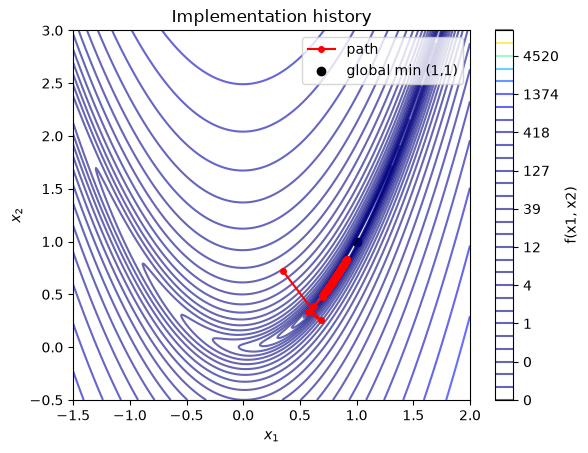

In [ ]:
import matplotlib.pyplot as plt

vectors = general_line_search(x0, 1e-1, "a")
path = np.array(vectors)

x1 = np.linspace(-1.5, 2.0, 400)
x2 = np.linspace(-0.5, 3.0, 400)
X1, X2 = np.meshgrid(x1, x2)
Z = (1 - X1) ** 2 + 100 * (X2 - X1**2) ** 2

plt.contour(X1, X2, Z, levels=np.logspace(-1, 4, 30),cmap="jet", alpha=0.6)
plt.colorbar(label="f(x1, x2)")
plt.plot(
    path[:, 0],
    path[:, 1],
    "ro-",
    linewidth=1.5,
    markersize=4,
    label="path",
)
plt.scatter(1, 1, color="black", label="global min (1,1)")
plt.xlabel("$x_1$")
plt.ylabel("$x_2$")
plt.title("Implementation history")
plt.legend()
plt.show()